## Stalked Ensemble Model for LMD
### RF and ANN with a ridge Meta Learner

### 1. Imports and Setup

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_validate, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
print("✓ Packages loaded successfully")


✓ Packages loaded successfully


### 2. Load Your Dataset

In [3]:

# Option 2: If in different folder, provide full path

df = pd.read_csv("~/Documents/PlayTime/LMD_Modelling/data/processed/processed_data.csv")

print(f"Loaded {len(df)} samples")
print(f"Columns: {df.columns.tolist()}")
df.head()

Loaded 89 samples
Columns: ['sample_id', 'Power', 'Speed', 'Feed', 'width_um', 'LED_J_per_mm', 'VED_J_per_mm3', 'height_um', 'depth_um', 'angle_deg', 'aspect_ratio', 'dilution_percent', 'porosity_%', 'pore_count', 'pore_area_um2', 'meltpool_area_um2', 'bbox_xyxy', 'speed_mm_per_s', 'meltpool_area_mm2', 'A_height_um2', 'A_depth_um2']


,sample_id,Power,Speed,Feed,width_um,LED_J_per_mm,VED_J_per_mm3,height_um,depth_um,angle_deg,...,dilution_percent,porosity_%,pore_count,pore_area_um2,meltpool_area_um2,bbox_xyxy,speed_mm_per_s,meltpool_area_mm2,A_height_um2,A_depth_um2
0,1.0_P1860.0_V1.1_F_2.0,1860,1.1,2,2288.6,101.454545,85.012065,294.92,476.93,179.92,...,61.790503,0.000,0,0.0,1193413.5,"[10.132645606994629, 390.0574035644531, 721.34...",18.333333,1.193413,674953.912,1091501.998
1,10.0_P2400.0_V1.5_F_4.5,2400,1.5,4,2480.8,96.000000,55.487128,488.73,583.10,-179.53,...,54.402284,0.000,0,0.0,1730131.0,"[63.66975402832031, 374.8359069824219, 826.238...",25.000000,1.730131,1212441.384,1446554.480
2,11.0_P1620.0_V0.9_F_3.0,1620,0.9,3,2039.2,108.000000,81.533734,547.71,416.26,179.72,...,43.181842,0.000,0,0.0,1324605.1,"[99.63111114501953, 375.4483947753906, 735.899...",15.000000,1.324605,1116890.232,848837.392
3,12.0_P2470.0_V1.0_F_7.0,2470,1.0,7,2653.1,148.200000,45.516137,995.99,729.72,178.91,...,42.285204,0.491,7,16001.3,3255988.1,"[21.937089920043945, 213.30682373046875, 835.4...",16.666667,3.255988,2642461.069,1936020.132
4,13.0_P2440.0_V1.4_F_7.5,2440,1.4,7,2497.9,104.571429,43.237318,859.49,579.73,179.07,...,40.280847,0.000,0,0.0,2418545.7,"[34.45549774169922, 269.4804382324219, 835.095...",23.333333,2.418546,2146920.071,1448107.567


### 3. Features and Preprocessing

In [ ]:
# Select process parameters as inputs
feature_cols = ['Power', 'Speed', 'Feed']
X = df[feature_cols].values
# Add heat input feature (physics-informed)
heat_input = X[:, 0] / (X[:, 1] + 1e-6)  # Power / Speed
X_engineered = np.column_stack([X, heat_input])

print(f"Features: {feature_cols + ['Heat_Input']}")
print(f"Shape: {X_engineered.shape}")

# Standardize features (CRITICAL for ANN)
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X_engineered)

# Select targets
y_height = df['height_um'].values
y_ar = df['aspect_ratio'].values

# Standardize targets
scaler_height = StandardScaler()
scaler_porosity = StandardScaler()
y_height_scaled = scaler_height.fit_transform(y_height.reshape(-1, 1)).ravel()
y_ar_scaled = scaler_porosity.fit_transform(y_ar.reshape(-1, 1)).ravel()

print(f"\nTarget ranges:")
print(f"  Height: [{y_height.min():.1f}, {y_height.max():.1f}] μm")
print(f"  Aspect Ratio: [{y_ar.min():.3f}, {y_ar.max():.3f}] ")

Features: ['Power', 'Speed', 'Feed', 'Heat_Input']
Shape: (89, 4)

Target ranges:
  Height: [214.0, 2432.2] μm
  Aspect Ratio: [0.078, 1.402] 


### 4: Build Stacking Models

In [16]:
# Building stacking Ensemble Models
print("Building stacking models...\n")

# --- Stacking for HEIGHT ---
stacking_height = StackingRegressor(
    estimators=[
        # Base Learner 1: Random Forest
        ('rf', RandomForestRegressor(
            n_estimators=200,          # 200 trees
            max_depth=None,            # No depth limit
            min_samples_leaf=2,        # Min 2 samples per leaf (regularization)
            max_features='sqrt',       # sqrt(n_features) per split
            random_state=42,
            n_jobs=-1                  # Use all CPU cores
        )),
        # Base Learner 2: Neural Network
        ('ann', MLPRegressor(
            hidden_layer_sizes=(64, 32),  # 4→64→32→1 architecture
            activation='relu',
            alpha=0.001,                  # L2 regularization
            learning_rate_init=0.001,
            max_iter=1000,
            early_stopping=True,          # Stop if no improvement
            validation_fraction=0.1,
            n_iter_no_change=20,
            random_state=42
        ))
    ],
    # Meta-Learner: Ridge regression
    final_estimator=Ridge(alpha=0.1),
    cv=5,           # 5-fold CV for out-of-fold predictions
    n_jobs=-1
)

# --- Stacking for POROSITY (same architecture) ---
stacking_porosity = StackingRegressor(
    estimators=[
        ('rf', RandomForestRegressor(
            n_estimators=200, max_depth=None, min_samples_leaf=2,
            max_features='sqrt', random_state=42, n_jobs=-1
        )),
        ('ann', MLPRegressor(
            hidden_layer_sizes=(64, 32), activation='relu', alpha=0.001,
            learning_rate_init=0.001, max_iter=1000, early_stopping=True,
            validation_fraction=0.1, n_iter_no_change=20, random_state=42
        ))
    ],                  
    final_estimator=Ridge(alpha=1.0),
    cv=5,
    n_jobs=-1
)

print("✓ Stacking models created")
print("  Architecture: Input → [RF, ANN] → Ridge → Output")
print("  CV Strategy: 5-fold for OOF predictions")

Building stacking models...

✓ Stacking models created
  Architecture: Input → [RF, ANN] → Ridge → Output
  CV Strategy: 5-fold for OOF predictions


### 5: Evaluation Function


In [17]:
# ============================================================================
# EVALUATION HELPER FUNCTION
# ============================================================================
def evaluate_model(model, X, y, model_name):
    """
    Evaluate model using 5-fold cross-validation.
    Returns dict with R², RMSE, MAE scores.
    """
    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    
    scores = cross_validate(
        model, X, y,
        cv=cv,
        scoring=['r2', 'neg_mean_squared_error', 'neg_mean_absolute_error'],
        n_jobs=-1
    )
    
    # Extract metrics
    r2 = scores['test_r2'].mean()
    r2_std = scores['test_r2'].std()
    rmse = np.sqrt(-scores['test_neg_mean_squared_error'].mean())
    rmse_std = np.sqrt(scores['test_neg_mean_squared_error'].std())
    mae = -scores['test_neg_mean_absolute_error'].mean()
    mae_std = scores['test_neg_mean_absolute_error'].std()
    
    print(f"{model_name:30s} R²={r2:.4f}±{r2_std:.4f}  RMSE={rmse:.4f}±{rmse_std:.4f}  MAE={mae:.4f}±{mae_std:.4f}")
    
    return {
        'r2': r2, 'r2_std': r2_std,
        'rmse': rmse, 'rmse_std': rmse_std,
        'mae': mae, 'mae_std': mae_std
    }

print("✓ Evaluation function ready")

✓ Evaluation function ready


### 6. Evaluate Height Models

In [18]:
# ============================================================================
# EVALUATE CLAD HEIGHT PREDICTION
# ============================================================================
print("="*90)
print("📏 CLAD HEIGHT PREDICTION - COMPARING MODELS")
print("="*90)

print("\n🔹 Baseline Models:")
# RF only
rf_height = RandomForestRegressor(
    n_estimators=200, max_depth=None, min_samples_leaf=2,
    random_state=42, n_jobs=-1
)
results_rf_h = evaluate_model(rf_height, X_scaled, y_height_scaled, "RF only")

# ANN only
ann_height = MLPRegressor(
    hidden_layer_sizes=(64, 32), alpha=0.001, max_iter=1000,
    early_stopping=True, random_state=42
)
results_ann_h = evaluate_model(ann_height, X_scaled, y_height_scaled, "ANN only")

print("\n🔸 Stacking Ensemble:")
results_stack_h = evaluate_model(stacking_height, X_scaled, y_height_scaled, 
                                  "Stacking (RF + ANN + Ridge)")

# Calculate improvement
improvement_h = ((results_stack_h['r2'] - results_rf_h['r2']) / results_rf_h['r2']) * 100
print(f"\n💡 Stacking improvement over RF: {improvement_h:+.1f}%")

📏 CLAD HEIGHT PREDICTION - COMPARING MODELS

🔹 Baseline Models:
RF only                        R²=0.8759±0.0269  RMSE=0.3620±0.3077  MAE=0.2340±0.0486
ANN only                       R²=0.9361±0.0240  RMSE=0.2519±0.1957  MAE=0.1720±0.0445

🔸 Stacking Ensemble:
Stacking (RF + ANN + Ridge)    R²=0.9078±0.0305  RMSE=0.2824±0.1389  MAE=0.2205±0.0228

💡 Stacking improvement over RF: +3.6%


### 7: Evaluate Porosity Models

In [19]:
# ============================================================================
# EVALUATE Aspect Ratio PREDICTION
# ============================================================================
print("\n" + "="*90)
print("🔬 Aspect Ratio PREDICTION - COMPARING MODELS")
print("="*90)

print("\n🔹 Baseline Models:")
# RF only
rf_porosity = RandomForestRegressor(
    n_estimators=200, max_depth=None, min_samples_leaf=2,
    random_state=42, n_jobs=-1
)
results_rf_p = evaluate_model(rf_porosity, X_scaled, y_ar_scaled, "RF only")

# ANN only
ann_porosity = MLPRegressor(
    hidden_layer_sizes=(64, 32), alpha=0.001, max_iter=1000,
    early_stopping=True, random_state=42
)
results_ann_p = evaluate_model(ann_porosity, X_scaled, y_ar_scaled, "ANN only")

print("\n🔸 Stacking Ensemble:")
results_stack_p = evaluate_model(stacking_porosity, X_scaled, y_ar_scaled,
                                  "Stacking (RF + ANN + Ridge)")

# Calculate improvement
improvement_p = ((results_stack_p['r2'] - results_rf_p['r2']) / results_rf_p['r2']) * 100
print(f"\n💡 Stacking improvement over RF: {improvement_p:+.1f}%")



🔬 Aspect Ratio PREDICTION - COMPARING MODELS

🔹 Baseline Models:
RF only                        R²=0.8049±0.0555  RMSE=0.4687±0.4457  MAE=0.2526±0.0733
ANN only                       R²=0.8685±0.0612  RMSE=0.4035±0.4253  MAE=0.1987±0.0860

🔸 Stacking Ensemble:
Stacking (RF + ANN + Ridge)    R²=0.8542±0.0454  RMSE=0.3899±0.3880  MAE=0.2254±0.0787

💡 Stacking improvement over RF: +6.1%


### 8: Summary Comparison (Optional)

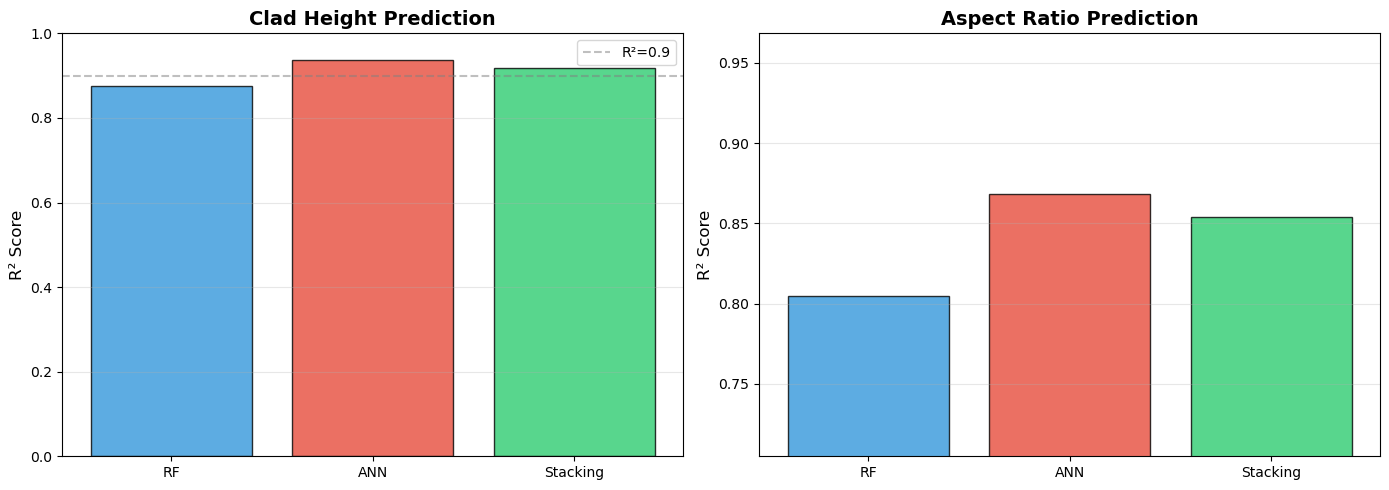


✓ Comparison plot saved as 'stacking_comparison.png'


In [15]:
# ============================================================================
# VISUAL COMPARISON
# ============================================================================
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Height comparison
models_h = ['RF', 'ANN', 'Stacking']
r2_h = [results_rf_h['r2'], results_ann_h['r2'], results_stack_h['r2']]
colors = ['#3498db', '#e74c3c', '#2ecc71']

axes[0].bar(models_h, r2_h, color=colors, alpha=0.8, edgecolor='black')
axes[0].set_ylabel('R² Score', fontsize=12)
axes[0].set_title('Clad Height Prediction', fontsize=14, fontweight='bold')
axes[0].set_ylim([0, 1])
axes[0].axhline(y=0.9, color='gray', linestyle='--', alpha=0.5, label='R²=0.9')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# Aspect Ratio comparison
models_p = ['RF', 'ANN', 'Stacking']
r2_p = [results_rf_p['r2'], results_ann_p['r2'], results_stack_p['r2']]

axes[1].bar(models_p, r2_p, color=colors, alpha=0.8, edgecolor='black')
axes[1].set_ylabel('R² Score', fontsize=12)
axes[1].set_title('Aspect Ratio Prediction', fontsize=14, fontweight='bold')
axes[1].set_ylim([min(r2_p)-0.1, max(r2_p)+0.1])
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('stacking_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Comparison plot saved as 'stacking_comparison.png'")
